In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

df = pd.read_csv('car_price.csv')

In [2]:
print("--- 1. Data Shape ---")
print(df.shape)

print("\n--- 2. Data Types ---")
print(df.info())


print("\n--- 3. Missing Values ---")
print(df.isnull().sum())


--- 1. Data Shape ---
(72435, 10)

--- 2. Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 72435 entries, 0 to 72434
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         68814 non-null  str    
 1   year          68813 non-null  float64
 2   price         68814 non-null  float64
 3   transmission  68812 non-null  str    
 4   mileage       68813 non-null  float64
 5   fuelType      68813 non-null  str    
 6   tax           68814 non-null  float64
 7   mpg           68814 non-null  float64
 8   engineSize    68813 non-null  float64
 9   Make          68814 non-null  str    
dtypes: float64(6), str(4)
memory usage: 5.5 MB
None

--- 3. Missing Values ---
model           3621
year            3622
price           3621
transmission    3623
mileage         3622
fuelType        3622
tax             3621
mpg             3621
engineSize      3622
Make            3621
dtype: int64


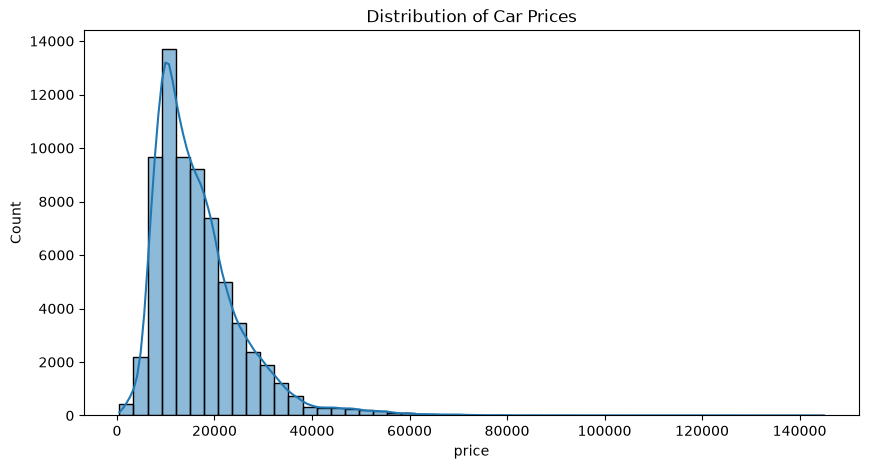

In [3]:
plt.figure(figsize=(10, 5))
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Distribution of Car Prices')
plt.show()


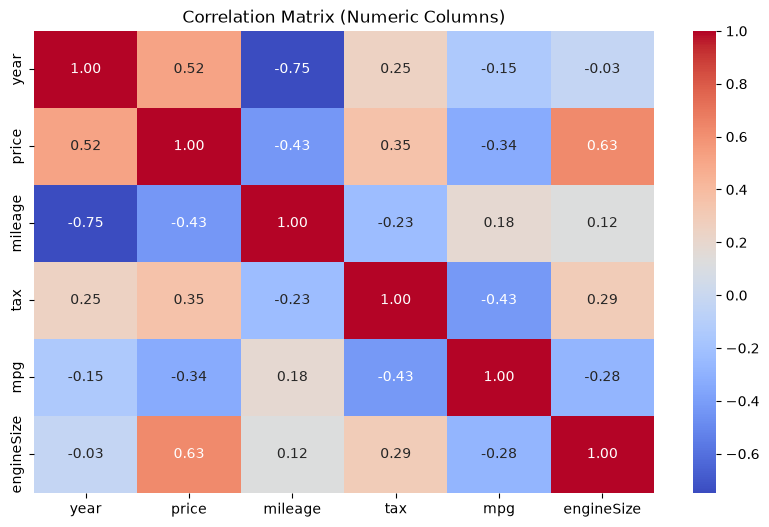

features seem most related to price is: engineSize


In [4]:
plt.figure(figsize=(10, 6))
correlation_matrix = df.select_dtypes(include=['number']).corr()
sns.heatmap(correlation_matrix,
            annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix (Numeric Columns)")
plt.show()

price_correlations = correlation_matrix['price']
top_feature = price_correlations.drop('price').abs().idxmax()
print(f"features seem most related to price is: {top_feature}")

In [5]:
df_clean = df.dropna().copy()
Q1 = df_clean['price'].quantile(0.25)
Q3 = df_clean['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df_clean = df_clean[(df_clean['price'] >= lower_bound) & (df_clean['price'] <= upper_bound)]


p33 = df_clean['price'].quantile(0.33)
p67 = df_clean['price'].quantile(0.67)

def categorize_price(price):
    if price <= p33:
        return 'Cheap'
    elif price <= p67:
        return 'Moderate'
    else:
        return 'Expensive'

df_clean['price_category'] = df_clean['price'].apply(categorize_price)
print("\n--- Number of cars in each category ---")
print(df_clean['price_category'].value_counts())

X_raw = df_clean.drop(columns=['price', 'price_category'])
X_encoded = pd.get_dummies(X_raw, drop_first=True)

# Define Targets
y_reg = df_clean['price']
y_class = df_clean['price_category']


--- Number of cars in each category ---
price_category
Moderate     14194
Cheap        13769
Expensive    13757
Name: count, dtype: int64


In [6]:
# Split Data 80/20
X_train, X_test, y_train_reg, y_test_reg, y_train_class, y_test_class = train_test_split(
    X_encoded, y_reg, y_class, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

--- Linear Regression Evaluation ---
RMSE: 2443.92
R2 Score: 0.8767


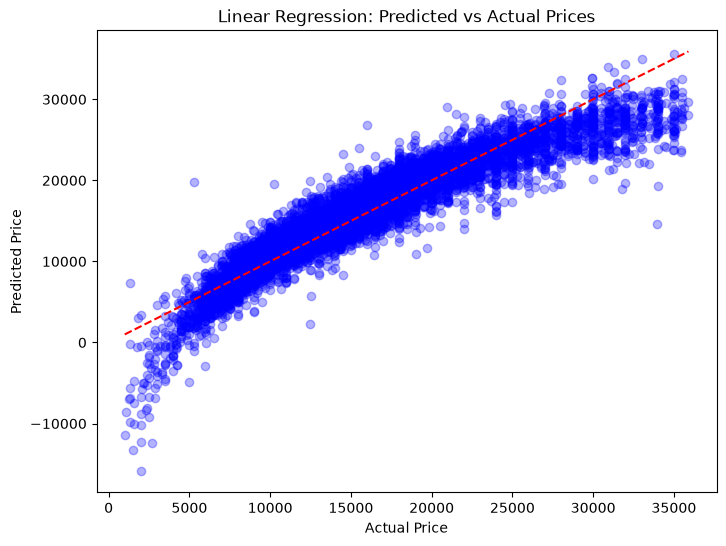

In [7]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train_reg)

# Predict & Evaluate
y_pred_reg = lr_model.predict(X_test_scaled)
print("--- Linear Regression Evaluation ---")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)):.2f}")
print(f"R2 Score: {r2_score(y_test_reg, y_pred_reg):.4f}")

# Predicted vs. Actual scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test_reg, y_pred_reg, alpha=0.3, color='blue')
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--')
plt.title('Linear Regression: Predicted vs Actual Prices')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.show()

In [ ]:
param_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'metric': ['euclidean', 'manhattan']
}

knn = KNeighborsClassifier()
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train_class)

print("--- KNN Classification ---")
print("Best Parameters:", grid_search.best_params_)

best_knn = grid_search.best_estimator_
y_pred_class = best_knn.predict(X_test_scaled)

print("\nAccuracy:", accuracy_score(y_test_class, y_pred_class))
print("Precision (Macro):", precision_score(y_test_class, y_pred_class, average='macro'))
print("Recall (Macro):", recall_score(y_test_class, y_pred_class, average='macro'))
print("F1-Score (Macro):", f1_score(y_test_class, y_pred_class, average='macro'))

cm = confusion_matrix(y_test_class, y_pred_class, labels=['Cheap', 'Moderate', 'Expensive'])
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Cheap', 'Moderate', 'Expensive'], yticklabels=['Cheap', 'Moderate', 'Expensive'])
plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

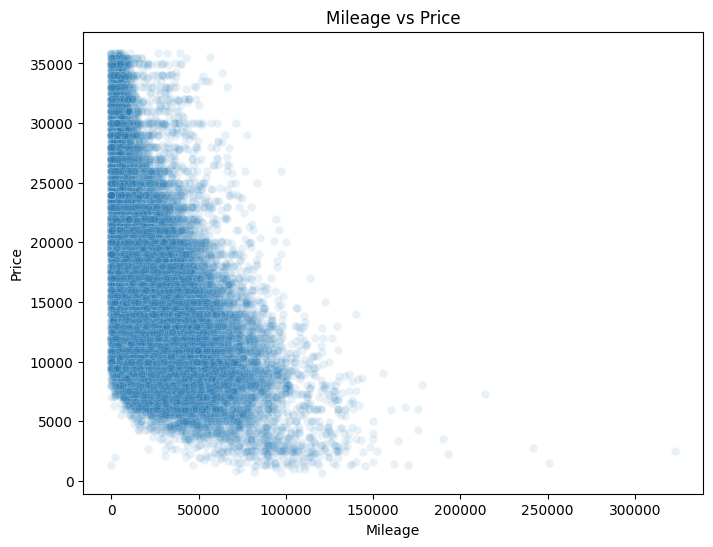

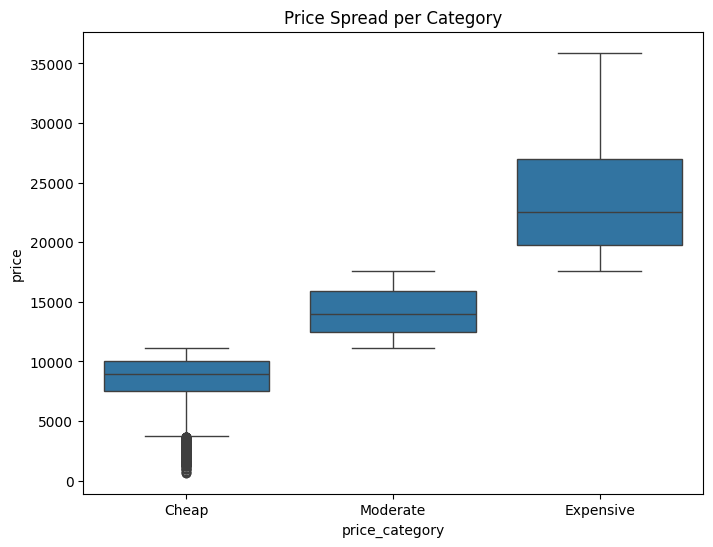

In [ ]:

plt.figure(figsize=(8, 6))
sns.scatterplot(x=df_clean['mileage'], y=df_clean['price'], alpha=0.1)
plt.title('Mileage vs Price')
plt.xlabel('Mileage')
plt.ylabel('Price')
plt.show()

plt.figure(figsize=(8, 6))
sns.boxplot(x='price_category', y='price', data=df_clean, order=['Cheap', 'Moderate', 'Expensive'])
plt.title('Price Spread per Category')
plt.show()

 Model Comparison

Which model performed better? Linear Regression performed very well (high R2 score), effectively capturing the exact numerical trends. KNN also performed well in accuracy.

Is classification easier? Generally, yes. Predicting an exact number (Regression) is mathematically harder than placing a value into a broad bucket (Classification).

Does converting price into categories lose information? Yes. A car costing  15,000  and one costing 20,000 might both be labeled "Moderate", losing the $5,000 variance detail.

 Sensitivity Analysis

Removing the most correlated feature (year/engineSize): Performance drops significantly in Regression because it relies heavily on these strong linear relationships.

Running KNN without scaling: Performance drops drastically! Since 'mileage' is in tens of thousands and 'engineSize' is between 1-5, mileage would completely dominate distance calculations, making the model inaccurate.

Different thresholds: Changing thresholds (e.g., using fixed numbers like $10k and 30k instead of percentiles) might create imbalanced classes (e.g., 80% Cheap, 5% Expensive), causing the KNN accuracy to artificially rise due to "majority class prediction" but reducing its actual predictive usefulness (F1-score drops).